# 013 - Regresión logística en la práctica
---

## Repaso

* La regresión logísitica es un **algoritmo de clasificación binaria** que utiliza la **función sigmoidea** para preedecir la probabilidad de un resultado como 0 ó 1
* **Entrada**: características (predictores) que se introducen en el modelo
* **Pesos**: coeficientes aprendidos durante el entrenamiento que representan la influencia de cada característica
* **Función sigmoidea**: convierte la suma ponderada de las entradas en una probabilidad entre 0 y 1
* **Predicción**: si la probabilidad es mayor o igual a 0.5, se clasifica el resultado como 1 (por ejemplo, "sí"); si es menor que 0.5, se lo clasifica como 0 (por ejemplo, "no")  

## 1. Importar bibliotecas

In [17]:
import numpy as np
import matplotlib.pyplot as plt

## 2. Generar o cargar datos

In [18]:
# Generating synthetic data for a binary classification problem
np.random.seed(0)
num_observations = 500

# Creating two clusters for class 0 and class 1
class_0 = np.random.multivariate_normal([30, 60], [[5, 1], [1, 5]], num_observations)
class_1 = np.random.multivariate_normal([40, 80], [[5, 1], [1, 5]], num_observations)

# Labels for the data
X = np.vstack((class_0, class_1))
y = np.hstack((np.zeros(num_observations), np.ones(num_observations)))

## 3. Función sigmoidea

In [19]:
# convierte la combinación lineal de pesos y características en una probabilidad
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

## 4. Función de costo (pérdida logarítmica)

In [20]:
# calcula el error entre los valores reales y los previstos. Mide el ajuste del modelo a los datos
def compute_cost(X, y, weights):
    m = len(y)
    z = np.dot(X, weights)
    predictions = sigmoid(z)
    cost = - (1/m) * np.sum(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))
    return cost

## 5. Descenso de gradiente

In [21]:
# minimiza la funciñon de costo ajustando los pesos
# tasa:  determina qué tan rápido nos acercamos al costo mínimo
# iteraciones: número de veces que ajustamos los pesos para alcanzar el mínimo
def gradient_descent(X, y, weights, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        z = np.dot(X, weights)
        predictions = sigmoid(z)
        gradient = np.dot(X.T, (predictions - y)) / m
        weights -= learning_rate * gradient
        cost = compute_cost(X, y, weights)
        cost_history.append(cost)
        
        # Print cost at every 100th iteration
        if i % 100 == 0:
            print(f"Iteration {i}, Cost: {cost}")
    
    return weights, cost_history

## 6. Agregar un término de intersección (sesgo)

In [22]:
intercept = np.ones((X.shape[0], 1))
X = np.hstack((intercept, X))
weights = np.zeros(X.shape[1])

## 7. Entrenamiento del modelo

In [23]:
learning_rate = 0.01
iterations = 1000

final_weights, cost_history = gradient_descent(X, y, weights, learning_rate, iterations)

Iteration 0, Cost: 1.8788968562821204
Iteration 100, Cost: 1.2120834764730533
Iteration 200, Cost: 1.972649090662833
Iteration 300, Cost: nan
Iteration 400, Cost: 1.130059414958078
Iteration 500, Cost: 11.817322483302824
Iteration 600, Cost: 8.854138357342661
Iteration 700, Cost: 6.593014907048336
Iteration 800, Cost: 2.359624322545805
Iteration 900, Cost: 6.039946768905951


/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_6355/562360493.py:6: RuntimeWarning: divide by zero encountered in log
  cost = - (1/m) * np.sum(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))
/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_6355/562360493.py:6: RuntimeWarning: invalid value encountered in multiply
  cost = - (1/m) * np.sum(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))


## 8. Visualización de función de costos

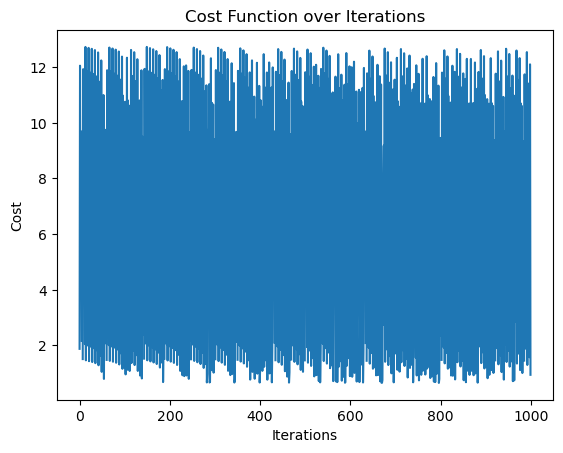

In [24]:
plt.plot(cost_history)
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost Function over Iterations')
plt.show()

El costo debería disminuir con cada iteración, lo que indica que el modelo está aprendiendo y mejorando

## 9. Hacer predicciones

In [25]:
def predict(X, weights):
    probabilities = sigmoid(np.dot(X, weights))
    return [1 if p >= 0.5 else 0 for p in probabilities]

# Predictions on our dataset
predictions = predict(X, final_weights)

* Con el modelo entrenado, se puede predecir si un nuevo cliente comprará el producto
* La función predict devuelve 1 si la probabilidad es 0.5 o superior; de lo contrario, devuelve 0

## 10. Evaluación del modelo

In [26]:
accuracy = np.mean(predictions == y) * 100
print(f'Accuracy: {accuracy:.2f}%')

Accuracy: 50.00%
